# CLEAR on NIH ChestX-ray14 dataset

In [1]:
# Import libraries and set the experiment configuration
import gc
import json
import random
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from sklearn.metrics import (accuracy_score, average_precision_score,
                             confusion_matrix, precision_recall_curve,
                             precision_recall_fscore_support, roc_auc_score, roc_curve)
from sklearn.model_selection import GroupShuffleSplit
from torch import nn
from torch.utils.data import DataLoader, Dataset, TensorDataset

SEED = 42
NUM_SEEDS = 20
MAX_EPOCHS = 200
PATIENCE = 10
IMAGE_BATCH_SIZE = 32
HEAD_BATCH_SIZE = 512
LEARNING_RATE = 2e-4
WEIGHT_DECAY = 0.0
NUM_WORKERS = 4
CONCEPT_CHUNK = 4096
LABELS = ['Atelectasis', 'Cardiomegaly', 'Consolidation', 'Edema',
          'Effusion', 'Emphysema', 'Fibrosis', 'Hernia', 'Infiltration',
          'Mass', 'Nodule', 'Pleural_Thickening', 'Pneumonia', 'Pneumothorax']
WORK = Path.cwd()
INPUT = WORK.parent / 'input'
RESULTS = WORK / 'clear_nih_results'
RESULTS.mkdir(parents=True, exist_ok=True)
RUN_START = time.perf_counter()
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
if not torch.cuda.is_available():
    raise RuntimeError('Select a GPU accelerator in notebook settings.')
DEVICE = torch.device('cuda:0')
print('GPU:', ', '.join(torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())))

GPU: Tesla T4, Tesla T4


In [2]:
# Install the official CLEAR package and record its revision
REPO = WORK / 'CLEAR_official'
if not (REPO / 'src/clear/hub.py').is_file():
    subprocess.run(['git', 'clone', '--depth', '1',
                    'https://github.com/peterhan91/CLEAR.git', str(REPO)], check=True)
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-e', str(REPO), 'timm'], check=True)
sys.path.insert(0, str(REPO / 'src'))
from clear import ConceptBank, ZeroShotPipeline, load_pretrained
CODE_REVISION = subprocess.check_output(
    ['git', '-C', str(REPO), 'rev-parse', 'HEAD'], text=True).strip()
print('CLEAR code revision:', CODE_REVISION[:12])

Cloning into '/kaggle/working/CLEAR_official'...


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 1.1 MB/s eta 0:00:00
CLEAR code revision: 57d2eae57dda


In [3]:
# Locate the NIH data and released CLEAR model assets
from huggingface_hub import HfApi, hf_hub_download

metadata_files = list(INPUT.rglob('Data_Entry_2017.csv'))
if not metadata_files:
    metadata_files = list(INPUT.rglob('Data_Entry_2017_v2020.csv'))
if len(metadata_files) != 1:
    raise FileNotFoundError('Add the complete NIH Chest X-rays dataset to Kaggle Inputs.')
DATA_FILE = metadata_files[0]
DATA_ROOT = DATA_FILE.parent
TRAIN_LIST = DATA_ROOT / 'train_val_list.txt'
TEST_LIST = DATA_ROOT / 'test_list.txt'
if not TRAIN_LIST.is_file() or not TEST_LIST.is_file():
    raise FileNotFoundError('The NIH input needs train_val_list.txt and test_list.txt.')

ASSET_NAMES = ['best_model.pt', 'mimic_concepts.csv',
               'concept_embeddings_368294.pt', 'concepts_embeddings_sfr_mistral.pickle']
attached = {name: list(INPUT.rglob(name)) for name in ASSET_NAMES}
missing = [name for name in ASSET_NAMES if not attached[name]]
HUB_REVISION = HfApi().model_info('peterhan91/CLEAR').sha if missing else None
ASSETS = {}
for name in ASSET_NAMES:
    if len(attached[name]) > 1:
        raise ValueError(f'Multiple CLEAR assets named {name}; keep one asset set.')
    ASSETS[name] = attached[name][0] if attached[name] else Path(
        hf_hub_download(repo_id='peterhan91/CLEAR', filename=name, revision=HUB_REVISION)
    )
print('NIH dataset:', DATA_ROOT)
print('CLEAR assets:', ', '.join(f'{name} ({ASSETS[name].stat().st_size / 1e9:.2f} GB)'
                                for name in ASSET_NAMES))
print('Hugging Face revision:', HUB_REVISION or 'attached local assets')

best_model.pt: reconstructing file:   0%|          |  0.00B /  603MB            

best_model.pt: downloading bytes:           |  0.00B            

mimic_concepts.csv: reconstructing file:   0%|          |  0.00B / 22.2MB            

mimic_concepts.csv: downloading bytes:           |  0.00B            

concept_embeddings_368294.pt: reconstructing file:   0%|          |  0.00B / 1.13GB            

concept_embeddings_368294.pt: downloading bytes:           |  0.00B            

concepts_embeddings_sfr_mistral.pickle: reconstructing file:   0%|          |  0.00B / 6.05GB            

concepts_embeddings_sfr_mistral.pickle: downloading bytes:           |  0.00B            

NIH dataset: /kaggle/input/datasets/nih-chest-xrays/data
CLEAR assets: best_model.pt (0.60 GB), mimic_concepts.csv (0.02 GB), concept_embeddings_368294.pt (1.13 GB), concepts_embeddings_sfr_mistral.pickle (6.05 GB)
Hugging Face revision: 142f169c8b006b0f28cf55c6a237c3003db5ed8f


In [4]:
# Build 14-label targets and patient-separated train, validation, and test sets
all_data = pd.read_csv(DATA_FILE)
required = {'Image Index', 'Finding Labels', 'Patient ID'}
if not required.issubset(all_data.columns):
    raise ValueError(f'NIH metadata is missing: {sorted(required - set(all_data.columns))}')
if len(all_data) != 112120 or all_data['Image Index'].duplicated().any():
    raise ValueError('Expected 112,120 unique NIH image rows.')
all_data = all_data.rename(columns={'Image Index': 'image_id',
                                    'Finding Labels': 'findings',
                                    'Patient ID': 'patient_id'})
finding_sets = all_data.findings.fillna('').map(lambda value: set(value.split('|')))
unknown = set().union(*finding_sets) - set(LABELS) - {'No Finding'}
if unknown:
    raise ValueError(f'Unexpected NIH labels: {sorted(unknown)}')
for label in LABELS:
    all_data[label] = finding_sets.map(lambda labels: float(label in labels)).astype('float32')

trainval_names = set(TRAIN_LIST.read_text().splitlines())
test_names = set(TEST_LIST.read_text().splitlines())
all_names = set(all_data.image_id)
if trainval_names & test_names or trainval_names | test_names != all_names:
    raise ValueError('NIH split lists overlap or do not cover every metadata image.')
trainval_df = all_data.loc[all_data.image_id.isin(trainval_names)].copy()
test_df = all_data.loc[all_data.image_id.isin(test_names)].copy()
overlap = set(trainval_df.patient_id) & set(test_df.patient_id)
if overlap:
    raise ValueError(f'The NIH split lists share {len(overlap)} patient IDs; '
                     'check the input version before evaluating.')
split = GroupShuffleSplit(n_splits=1, test_size=0.10, random_state=SEED)
train_rows, val_rows = next(split.split(trainval_df, groups=trainval_df.patient_id))
train_df = trainval_df.iloc[train_rows].reset_index(drop=True)
val_df = trainval_df.iloc[val_rows].reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

image_paths = {}
for path in DATA_ROOT.rglob('*.png'):
    if 'images' in path.parts or any(part.startswith('images_') for part in path.parts):
        if path.name in image_paths:
            raise ValueError(f'Duplicate NIH image filename: {path.name}')
        image_paths[path.name] = path
missing_images = all_names - set(image_paths)
if missing_images:
    raise FileNotFoundError(f'{len(missing_images):,} NIH images are missing; '
                            f'first: {sorted(missing_images)[0]}')
for frame in (train_df, val_df, test_df):
    frame['image_path'] = frame.image_id.map(image_paths)
for name, frame in [('Train', train_df), ('Validation', val_df), ('Test', test_df)]:
    print(f'{name}: {len(frame):,} images from {frame.patient_id.nunique():,} patients')
print('Positive images by finding:')
print(pd.DataFrame({'train': train_df[LABELS].sum().astype(int),
                    'validation': val_df[LABELS].sum().astype(int),
                    'test': test_df[LABELS].sum().astype(int)}).to_string())
if any(frame[LABELS].sum().min() == 0 for frame in (train_df, val_df, test_df)):
    raise ValueError('At least one finding has no positives in a split; choose another seed.')

Train: 77,988 images from 25,207 patients
Validation: 8,536 images from 2,801 patients
Test: 25,596 images from 2,797 patients
Positive images by finding:
                    train  validation  test
Atelectasis          7405         875  3279
Cardiomegaly         1549         158  1069
Consolidation        2584         268  1815
Edema                1253         125   925
Effusion             7852         807  4658
Emphysema            1317         106  1093
Fibrosis             1111         140   435
Hernia                122          19    86
Infiltration        12480        1302  6112
Mass                 3646         388  1748
Nodule               4247         461  1623
Pleural_Thickening   1997         245  1143
Pneumonia             782          94   555
Pneumothorax         2394         243  2665


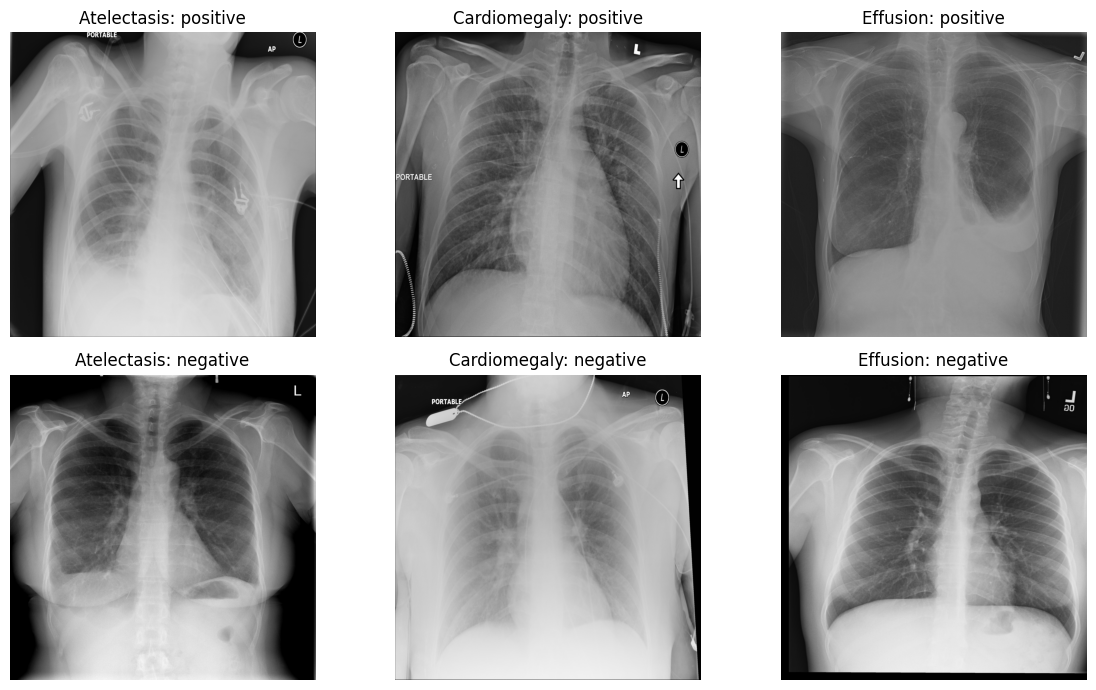

In [5]:
# Display positive and negative training examples before feature extraction
def read_xray(path):
    with Image.open(path) as image:
        return image.convert('RGB')

sample_labels = ['Atelectasis', 'Cardiomegaly', 'Effusion']
fig, axes = plt.subplots(2, len(sample_labels), figsize=(12, 7))
for col, label in enumerate(sample_labels):
    for row, target in enumerate((1, 0)):
        choices = train_df.loc[train_df[label] == target]
        sample = choices.sample(n=1, random_state=SEED + col + row).iloc[0]
        axes[row, col].imshow(read_xray(sample.image_path))
        axes[row, col].set_title(f'{label}: {"positive" if target else "negative"}')
        axes[row, col].axis('off')
fig.tight_layout()
fig.savefig(RESULTS / 'sample_images.png', dpi=160)
plt.show()
plt.close(fig)

In [6]:
# Load CLEAR's official checkpoint and 448-pixel image transform
model, preprocess = load_pretrained(checkpoint_path=ASSETS['best_model.pt'], device=DEVICE)
model.requires_grad_(False).eval()

class CLEARImages(Dataset):
    def __init__(self, frame):
        self.paths = frame['image_path'].tolist()
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, index):
        image = read_xray(self.paths[index])
        return preprocess(image)

class ImageEncoder(nn.Module):
    def __init__(self, clear_model):
        super().__init__()
        self.clear_model = clear_model
    def forward(self, images):
        return self.clear_model.encode_image(images)

encoder = ImageEncoder(model).eval()
if torch.cuda.device_count() > 1:
    encoder = nn.DataParallel(encoder)

def image_loader(frame):
    return DataLoader(CLEARImages(frame), batch_size=IMAGE_BATCH_SIZE, shuffle=False,
                      num_workers=NUM_WORKERS, pin_memory=True,
                      persistent_workers=NUM_WORKERS > 0)

small_batch = next(iter(image_loader(train_df.head(2)))).to(DEVICE)
with torch.inference_mode(), torch.autocast('cuda', dtype=torch.float16):
    small_features = encoder(small_batch)
if small_features.shape != (2, 768):
    raise ValueError(f'Unexpected CLEAR image feature shape: {tuple(small_features.shape)}')
print('CLEAR image features:', tuple(small_features.shape), '| input:', tuple(small_batch.shape))
del small_batch, small_features

Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


CLEAR image features: (2, 768) | input: (2, 3, 448, 448)


In [7]:
# Load and align the complete 368,294-concept bank
concept_table = pd.read_csv(ASSETS['mimic_concepts.csv'])
if 'concept' not in concept_table or 'concept_idx' not in concept_table:
    raise ValueError('CLEAR concept CSV must contain concept and concept_idx columns.')
indices = concept_table['concept_idx'].to_numpy()
if not np.array_equal(indices, np.arange(len(indices))):
    raise ValueError('CLEAR concepts must be ordered by contiguous concept_idx values.')
bank = ConceptBank.from_files(
    ASSETS['mimic_concepts.csv'],
    clip_embeddings_path=ASSETS['concept_embeddings_368294.pt'],
    llm_embeddings_path=ASSETS['concepts_embeddings_sfr_mistral.pickle'],
    allow_unsafe_pickle=True,
)
bank.concepts = tuple(concept_table['concept'].astype(str))
if bank.num_concepts != 368294 or bank.clip_embeddings.shape != (368294, 768) \
        or bank.llm_embeddings.shape != (368294, 4096):
    raise ValueError('CLEAR concept assets have unexpected or misaligned shapes.')
print('Concept bank:', bank.num_concepts, '| text features:', bank.clip_embeddings.shape,
      '| LLM embeddings:', bank.llm_embeddings.shape)
del concept_table
gc.collect()

/kaggle/working/CLEAR_official/src/clear/concepts.py:298: RuntimeWarning: Unpickling /root/.cache/huggingface/hub/models--peterhan91--CLEAR/snapshots/142f169c8b006b0f28cf55c6a237c3003db5ed8f/concepts_embeddings_sfr_mistral.pickle; only trusted pickle files should be loaded.
  _load_array(


Concept bank: 368294 | text features: (368294, 768) | LLM embeddings: (368294, 4096)


0

In [8]:
# Precompute the full CLEAR projection
projection_start = time.perf_counter()
projection = torch.zeros((768, 4096), device=DEVICE, dtype=torch.float32)
with torch.inference_mode():
    for start in range(0, bank.num_concepts, CONCEPT_CHUNK):
        stop = min(start + CONCEPT_CHUNK, bank.num_concepts)
        text_chunk = torch.from_numpy(bank.clip_embeddings[start:stop]).to(DEVICE)
        llm_chunk = torch.from_numpy(bank.llm_embeddings[start:stop]).to(DEVICE)
        projection.add_(F.normalize(text_chunk, dim=1).T @ llm_chunk)
        del text_chunk, llm_chunk
projection_seconds = time.perf_counter() - projection_start
torch.save(projection.cpu(), RESULTS / 'clear_projection.pt')

reference = ZeroShotPipeline(model, bank, concept_chunk_size=8192, device=DEVICE)
check_image = preprocess(read_xray(train_df.iloc[0]['image_path'])).unsqueeze(0).to(DEVICE)
with torch.inference_mode():
    image_feature = F.normalize(model.encode_image(check_image).float(), dim=-1)
    official_output = reference.project_to_concept_space(image_feature)
    fast_output = F.normalize(image_feature @ projection, dim=-1)
max_difference = (official_output - fast_output).abs().max().item()
if max_difference > 1e-3:
    raise RuntimeError(f'CLEAR projection check failed: maximum difference {max_difference:.6f}')
print(f'Full projection verified: maximum difference {max_difference:.6f}; '
      f'precomputation {projection_seconds / 60:.1f} minutes')
del reference, check_image, image_feature, official_output, fast_output
gc.collect()

Full projection verified: maximum difference 0.000000; precomputation 0.0 minutes


9

In [9]:
# Extract frozen 4,096-dimensional CLEAR concept features for all three splits
def extract_features(frame, name):
    path = RESULTS / f'{name}_features.npy'
    vectors = np.lib.format.open_memmap(path, mode='w+', dtype='float32',
                                         shape=(len(frame), 4096))
    start_time = time.perf_counter()
    offset = 0
    with torch.inference_mode():
        for batch in image_loader(frame):
            batch = batch.to(DEVICE, non_blocking=True)
            with torch.autocast('cuda', dtype=torch.float16):
                image_features = encoder(batch)
            image_features = F.normalize(image_features.float(), dim=-1)
            concept_features = F.normalize(image_features @ projection, dim=-1)
            count = len(batch)
            vectors[offset:offset + count] = concept_features.cpu().numpy()
            offset += count
    vectors.flush()
    minutes = (time.perf_counter() - start_time) / 60
    print(f'{name}: {offset:,} images | {minutes:.1f} min | {path.name}')
    return vectors, minutes

train_x, train_minutes = extract_features(train_df, 'train')
val_x, val_minutes = extract_features(val_df, 'validation')
test_x, test_minutes = extract_features(test_df, 'test')
train_y = train_df[LABELS].to_numpy(dtype='float32')
val_y = val_df[LABELS].to_numpy(dtype='float32')
test_y = test_df[LABELS].to_numpy(dtype='float32')

train: 77,988 images | 25.5 min | train_features.npy
validation: 8,536 images | 2.8 min | validation_features.npy
test: 25,596 images | 8.6 min | test_features.npy


In [10]:
# Train 20 independent linear heads with paper settings
def head_loader(features, labels, shuffle=False, generator=None):
    dataset = TensorDataset(torch.from_numpy(features), torch.from_numpy(labels))
    return DataLoader(dataset, batch_size=HEAD_BATCH_SIZE, shuffle=shuffle,
                      generator=generator, num_workers=0, pin_memory=True)

val_loader = head_loader(val_x, val_y)
loss_fn = nn.BCEWithLogitsLoss()
all_history = []
seed_records = []
training_start = time.perf_counter()
for seed in range(SEED, SEED + NUM_SEEDS):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    generator = torch.Generator().manual_seed(seed)
    train_loader = head_loader(train_x, train_y, shuffle=True, generator=generator)
    head = nn.Linear(4096, len(LABELS)).to(DEVICE)
    optimizer = torch.optim.Adam(head.parameters(), lr=LEARNING_RATE,
                                 weight_decay=WEIGHT_DECAY)
    best_auc, best_epoch, stale = -1.0, 0, 0
    seed_start = time.perf_counter()
    for epoch in range(1, MAX_EPOCHS + 1):
        head.train()
        train_total = 0.0
        for features, labels in train_loader:
            features = features.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            loss = loss_fn(head(features), labels)
            loss.backward()
            optimizer.step()
            train_total += loss.item() * len(features)
        head.eval()
        val_total = 0.0
        val_prob_batches = []
        with torch.inference_mode():
            for features, labels in val_loader:
                features = features.to(DEVICE, non_blocking=True)
                labels = labels.to(DEVICE, non_blocking=True)
                logits = head(features)
                val_total += loss_fn(logits, labels).item() * len(features)
                val_prob_batches.append(logits.sigmoid().cpu().numpy())
        val_prob_epoch = np.concatenate(val_prob_batches)
        val_aucs = [roc_auc_score(val_y[:, j], val_prob_epoch[:, j])
                    if len(np.unique(val_y[:, j])) == 2 else np.nan
                    for j in range(len(LABELS))]
        val_auc = float(np.nanmean(val_aucs))
        train_loss = train_total / len(train_df)
        val_loss = val_total / len(val_df)
        all_history.append({'seed': seed, 'epoch': epoch, 'train_loss': train_loss,
                            'val_loss': val_loss, 'val_macro_auroc': val_auc})
        if val_auc > best_auc:
            best_auc, best_epoch, stale = val_auc, epoch, 0
            torch.save(head.state_dict(), RESULTS / f'best_head_seed_{seed}.pt')
        else:
            stale += 1
        if epoch == 1 or epoch % 10 == 0 or stale >= PATIENCE:
            print(f'Seed {seed - SEED + 1:02d}/{NUM_SEEDS} | epoch {epoch:03d}/{MAX_EPOCHS} | '
                  f'train {train_loss:.4f} | val {val_loss:.4f} | val AUROC {val_auc:.3f}')
        if stale >= PATIENCE:
            print(f'Seed {seed}: early stop at epoch {epoch}; best epoch {best_epoch}.')
            break
    seed_minutes = (time.perf_counter() - seed_start) / 60
    seed_records.append({'seed': seed, 'best_epoch': best_epoch,
                         'best_val_macro_auroc': best_auc,
                         'head_training_minutes': seed_minutes})
    del train_loader, head, optimizer
    torch.cuda.empty_cache()

training_minutes = (time.perf_counter() - training_start) / 60
representative = max(seed_records, key=lambda row: row['best_val_macro_auroc'])
representative_seed = representative['seed']
best_epoch = representative['best_epoch']
history = [row for row in all_history if row['seed'] == representative_seed]
head = nn.Linear(4096, len(LABELS)).to(DEVICE)
head.load_state_dict(torch.load(RESULTS / f'best_head_seed_{representative_seed}.pt',
                                map_location=DEVICE, weights_only=True))
head.eval()
torch.save(head.state_dict(), RESULTS / 'best_head.pt')
print(f'All seeds finished in {training_minutes:.1f} minutes. '
      f'Representative seed {representative_seed}: validation AUROC '
      f'{representative["best_val_macro_auroc"]:.3f} at epoch {best_epoch}.')

Seed 01/20 | epoch 001/200 | train 0.4641 | val 0.3144 | val AUROC 0.506
Seed 01/20 | epoch 010/200 | train 0.1597 | val 0.1572 | val AUROC 0.658
Seed 01/20 | epoch 020/200 | train 0.1539 | val 0.1518 | val AUROC 0.702
Seed 01/20 | epoch 030/200 | train 0.1501 | val 0.1480 | val AUROC 0.730
Seed 01/20 | epoch 040/200 | train 0.1473 | val 0.1452 | val AUROC 0.751
Seed 01/20 | epoch 050/200 | train 0.1453 | val 0.1432 | val AUROC 0.767
Seed 01/20 | epoch 060/200 | train 0.1438 | val 0.1418 | val AUROC 0.779
Seed 01/20 | epoch 070/200 | train 0.1426 | val 0.1407 | val AUROC 0.787
Seed 01/20 | epoch 080/200 | train 0.1418 | val 0.1399 | val AUROC 0.793
Seed 01/20 | epoch 090/200 | train 0.1411 | val 0.1392 | val AUROC 0.796
Seed 01/20 | epoch 100/200 | train 0.1405 | val 0.1387 | val AUROC 0.799
Seed 01/20 | epoch 110/200 | train 0.1401 | val 0.1383 | val AUROC 0.800
Seed 01/20 | epoch 120/200 | train 0.1397 | val 0.1379 | val AUROC 0.802
Seed 01/20 | epoch 130/200 | train 0.1394 | val 0.1

In [11]:
# Evaluate every seed
def predict(features, model):
    parts = []
    with torch.inference_mode():
        for start in range(0, len(features), 4096):
            batch = torch.from_numpy(np.asarray(features[start:start + 4096])).to(DEVICE)
            parts.append(model(batch).sigmoid().cpu().numpy())
    return np.concatenate(parts)

def choose_thresholds(probabilities):
    chosen = {}
    for j, label in enumerate(LABELS):
        precision, recall, choices = precision_recall_curve(val_y[:, j], probabilities[:, j])
        f1_values = 2 * precision[:-1] * recall[:-1] / np.maximum(
            precision[:-1] + recall[:-1], 1e-12)
        chosen[label] = float(choices[np.argmax(f1_values)])
    return chosen

evaluation_start = time.perf_counter()
metric_rows = []
predictions = None
for record in seed_records:
    seed = record['seed']
    head.load_state_dict(torch.load(RESULTS / f'best_head_seed_{seed}.pt',
                                    map_location=DEVICE, weights_only=True))
    head.eval()
    current_val_probs = predict(val_x, head)
    current_thresholds = choose_thresholds(current_val_probs)
    current_test_probs = predict(test_x, head)
    for j, label in enumerate(LABELS):
        truth = test_y[:, j].astype(int)
        probability = current_test_probs[:, j]
        predicted = (probability >= current_thresholds[label]).astype(int)
        precision, recall, f1, _ = precision_recall_fscore_support(
            truth, predicted, average='binary', zero_division=0)
        metric_rows.append({
            'seed': seed, 'label': label,
            'AUROC': roc_auc_score(truth, probability) if len(np.unique(truth)) == 2 else np.nan,
            'AUPRC': average_precision_score(truth, probability) if truth.sum() else np.nan,
            'accuracy': accuracy_score(truth, predicted),
            'precision': precision, 'recall': recall, 'F1': f1,
            'threshold': current_thresholds[label], 'positive_count': int(truth.sum()),
        })
    if seed == representative_seed:
        val_probs = current_val_probs
        thresholds = current_thresholds
        test_probs = current_test_probs
        predictions = test_df[['image_id']].copy()
        for j, label in enumerate(LABELS):
            predictions[f'target_{label}'] = test_y[:, j].astype(int)
            predictions[f'probability_{label}'] = test_probs[:, j]
            predictions[f'prediction_{label}'] = (
                test_probs[:, j] >= thresholds[label]).astype(int)
    seed_metrics = pd.DataFrame(metric_rows).loc[lambda frame: frame.seed == seed]
    record['test_macro_auroc'] = float(seed_metrics.AUROC.mean())
    print(f'Seed {seed}: NIH test macro AUROC '
          f'{record["test_macro_auroc"]:.3f}')

evaluation_seconds = time.perf_counter() - evaluation_start
head.load_state_dict(torch.load(RESULTS / 'best_head.pt',
                                map_location=DEVICE, weights_only=True))
head.eval()
metrics_by_seed_df = pd.DataFrame(metric_rows)
aggregate_metrics_df = metrics_by_seed_df.groupby('label', sort=False)[
    ['AUROC', 'AUPRC', 'accuracy', 'precision', 'recall', 'F1', 'threshold']
].agg(['mean', 'std'])
metrics_df = metrics_by_seed_df.loc[
    metrics_by_seed_df.seed == representative_seed].set_index('label')
metrics = metrics_df.to_dict(orient='index')
seed_summary_df = pd.DataFrame(seed_records)
macro_mean = seed_summary_df.test_macro_auroc.mean()
macro_std = seed_summary_df.test_macro_auroc.std()
print('NIH test metrics across 20 seeds (mean ± standard deviation):')
print(aggregate_metrics_df.round(3).to_string())
print(f'Macro AUROC: {macro_mean:.3f} ± {macro_std:.3f}')
print(f'Representative seed {representative_seed} is used for figures and attribution.')

Seed 42: NIH test macro AUROC 0.778
Seed 43: NIH test macro AUROC 0.778
Seed 44: NIH test macro AUROC 0.778
Seed 45: NIH test macro AUROC 0.778
Seed 46: NIH test macro AUROC 0.778
Seed 47: NIH test macro AUROC 0.778
Seed 48: NIH test macro AUROC 0.778
Seed 49: NIH test macro AUROC 0.778
Seed 50: NIH test macro AUROC 0.778
Seed 51: NIH test macro AUROC 0.778
Seed 52: NIH test macro AUROC 0.778
Seed 53: NIH test macro AUROC 0.778
Seed 54: NIH test macro AUROC 0.778
Seed 55: NIH test macro AUROC 0.778
Seed 56: NIH test macro AUROC 0.778
Seed 57: NIH test macro AUROC 0.778
Seed 58: NIH test macro AUROC 0.778
Seed 59: NIH test macro AUROC 0.778
Seed 60: NIH test macro AUROC 0.778
Seed 61: NIH test macro AUROC 0.778
NIH test metrics across 20 seeds (mean ± standard deviation):
                    AUROC       AUPRC      accuracy        precision        recall            F1        threshold       
                     mean  std   mean  std     mean    std      mean    std   mean    std   mean 

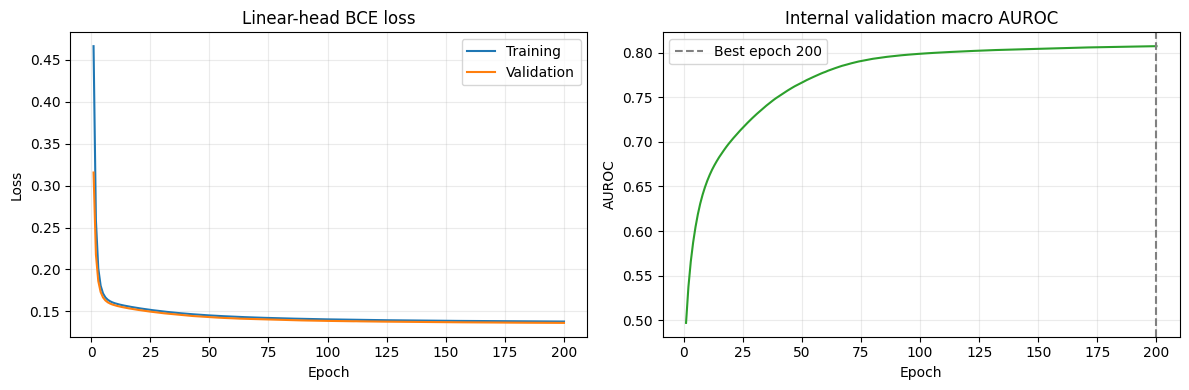

In [12]:
# Plot training and validation curves
history_df = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_df.epoch, history_df.train_loss, label='Training')
axes[0].plot(history_df.epoch, history_df.val_loss, label='Validation')
axes[0].set(title='Linear-head BCE loss', xlabel='Epoch', ylabel='Loss')
axes[0].legend()
axes[1].plot(history_df.epoch, history_df.val_macro_auroc, color='tab:green')
axes[1].axvline(best_epoch, color='gray', linestyle='--', label=f'Best epoch {best_epoch}')
axes[1].set(title='Internal validation macro AUROC', xlabel='Epoch', ylabel='AUROC')
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(RESULTS / 'learning_curves.png', dpi=180)
plt.show()
plt.close(fig)

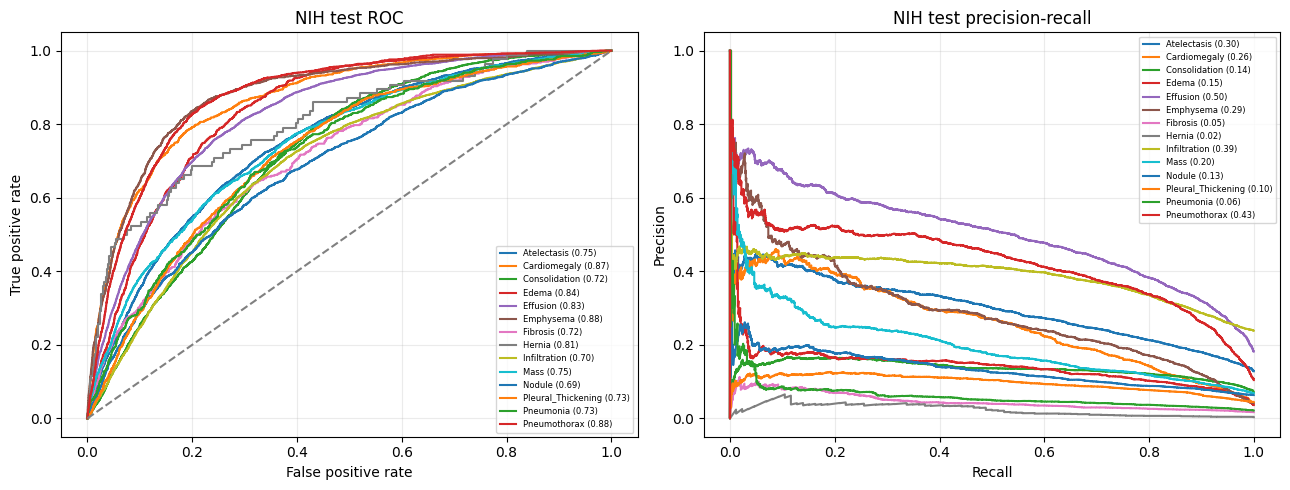

In [13]:
# Plot ROC and precision-recall curves
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for j, label in enumerate(LABELS):
    truth = test_y[:, j].astype(int)
    if len(np.unique(truth)) < 2:
        continue
    fpr, tpr, _ = roc_curve(truth, test_probs[:, j])
    precision, recall, _ = precision_recall_curve(truth, test_probs[:, j])
    axes[0].plot(fpr, tpr, label=f'{label} ({metrics[label]["AUROC"]:.2f})')
    axes[1].plot(recall, precision, label=f'{label} ({metrics[label]["AUPRC"]:.2f})')
axes[0].plot([0, 1], [0, 1], '--', color='gray')
axes[0].set(title='NIH test ROC', xlabel='False positive rate', ylabel='True positive rate')
axes[1].set(title='NIH test precision-recall', xlabel='Recall', ylabel='Precision')
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=6)
fig.tight_layout()
fig.savefig(RESULTS / 'roc_pr_curves.png', dpi=180)
plt.show()
plt.close(fig)

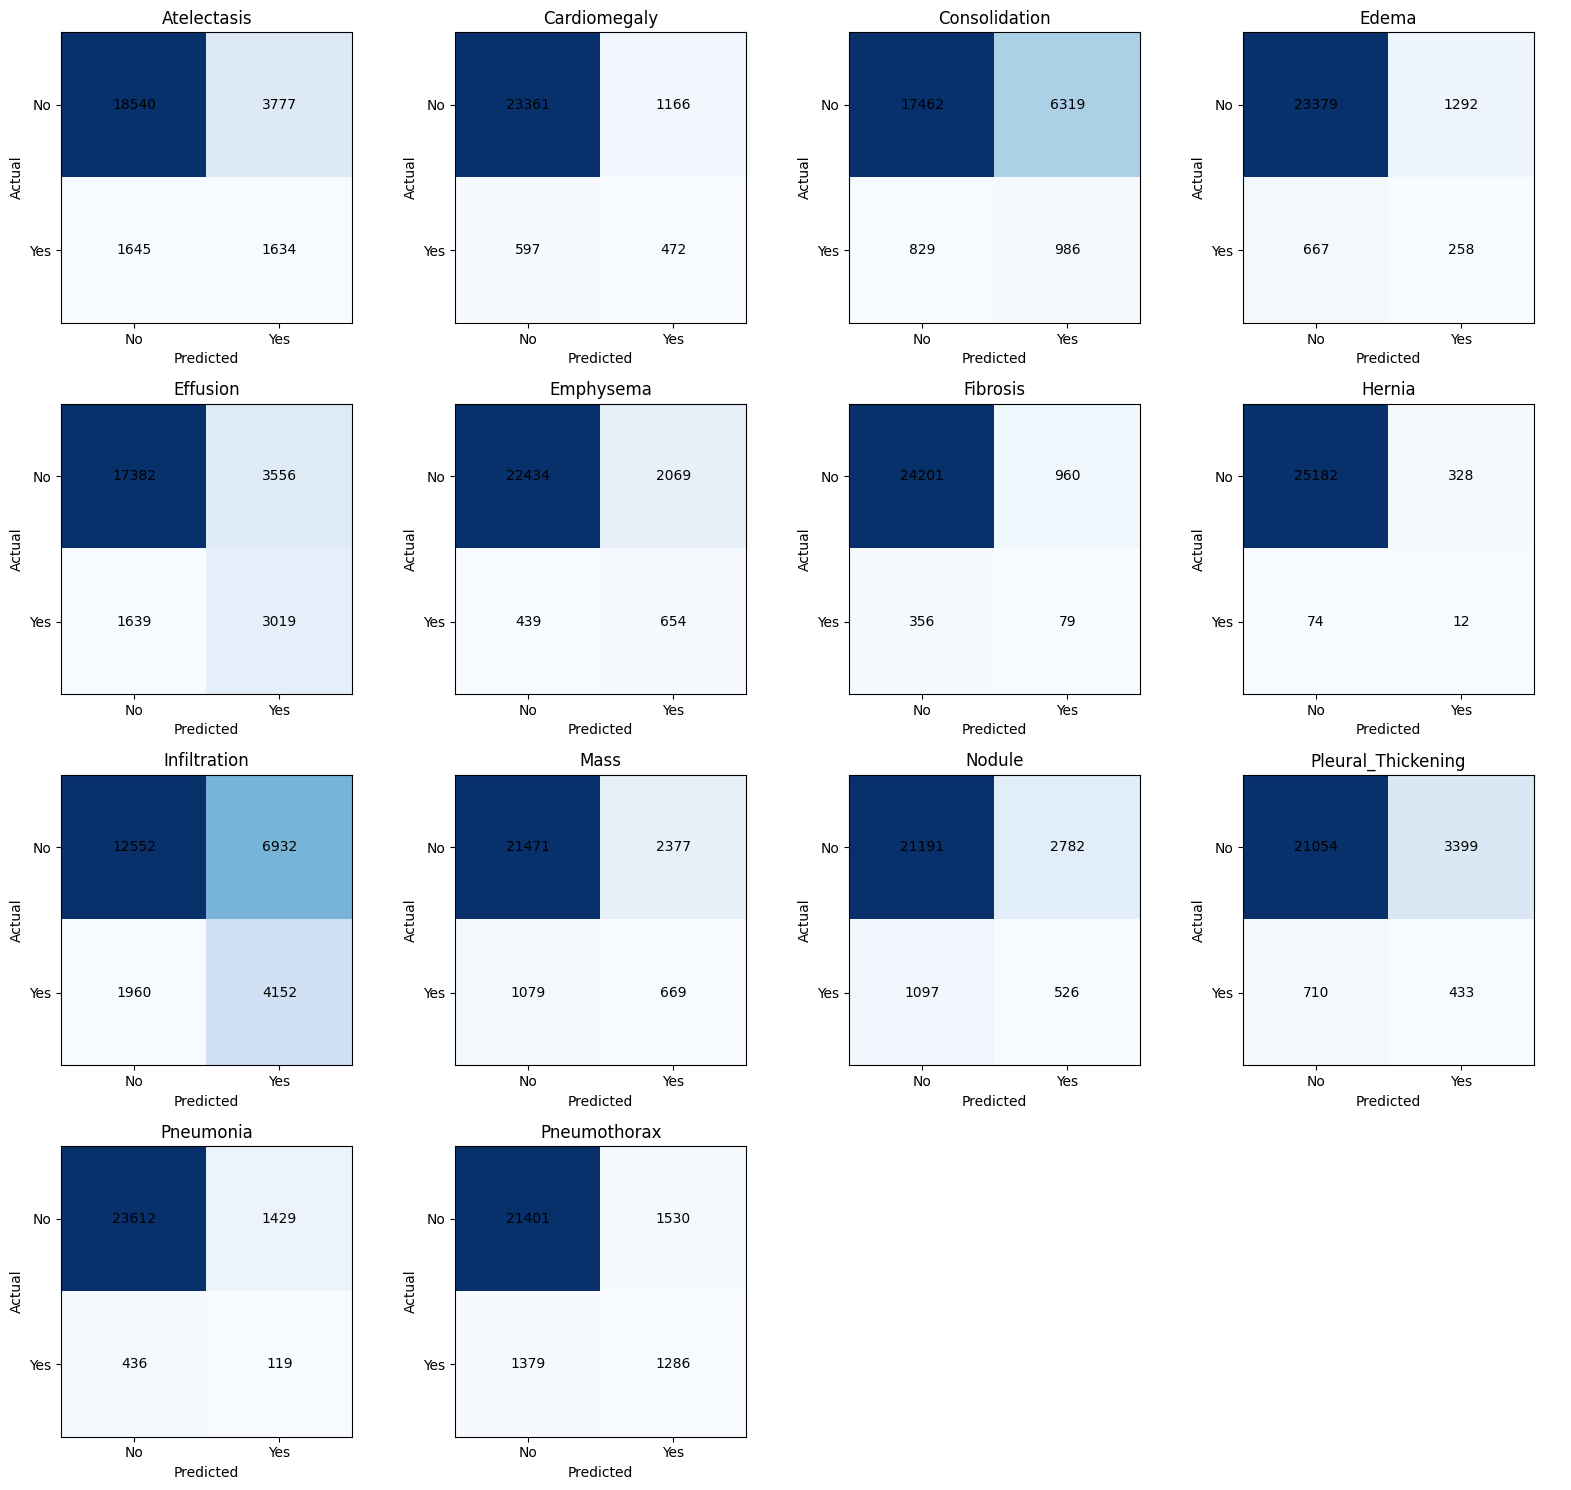

In [14]:
# Plot one confusion matrix for each NIH finding
fig, axes = plt.subplots(4, 4, figsize=(16, 15))
for index, label in enumerate(LABELS):
    ax = axes.flat[index]
    matrix = confusion_matrix(test_y[:, index].astype(int),
                              (test_probs[:, index] >= thresholds[label]).astype(int),
                              labels=[0, 1])
    ax.imshow(matrix, cmap='Blues')
    for row in range(2):
        for col in range(2):
            ax.text(col, row, str(matrix[row, col]), ha='center', va='center')
    ax.set(title=label, xlabel='Predicted', ylabel='Actual', xticks=[0, 1], yticks=[0, 1],
           xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
for ax in axes.flat[len(LABELS):]:
    ax.axis('off')
fig.tight_layout()
fig.savefig(RESULTS / 'confusion_matrices.png', dpi=180)
plt.show()
plt.close(fig)

In [15]:
# Rank concepts by alignment with the learned Effusion classifier
audit_label = 'Effusion'
audit_index = LABELS.index(audit_label)
class_weight = F.normalize(head.weight[audit_index].detach(), dim=0)
alignments = np.empty(bank.num_concepts, dtype='float32')
with torch.inference_mode():
    for start in range(0, bank.num_concepts, CONCEPT_CHUNK):
        stop = min(start + CONCEPT_CHUNK, bank.num_concepts)
        llm = torch.from_numpy(bank.llm_embeddings[start:stop]).to(DEVICE)
        alignments[start:stop] = (F.normalize(llm, dim=1) @ class_weight).cpu().numpy()

top_positive = np.argsort(alignments)[-10:][::-1]
top_negative = np.argsort(alignments)[:10]
audit_df = pd.DataFrame([{'direction': direction, 'concept': bank.concepts[int(i)],
                          'alignment': float(alignments[i])}
                         for direction, ids in [('supports', top_positive),
                                                ('opposes', top_negative)] for i in ids])
print('Class concept alignment:', audit_label)
print(audit_df.to_string(index=False))
audit_df.to_csv(RESULTS / 'concept_alignment.csv', index=False)

Class concept alignment: Effusion
direction                                                                                              concept  alignment
 supports                             left pleural effusion has increased in size and is now small to moderate   0.289690
 supports bilateral pleural effusions have increased, now small-to-moderate on the left and small on the right   0.287096
 supports                                                           increase in amount of the pleural effusion   0.285907
 supports                                                   increasing small-to-moderate left pleural effusion   0.284958
 supports                                                                          increasing pleural effusion   0.283114
 supports                                        small to moderate left pleural effusion has increased in size   0.283074
 supports                                             increasing small to moderate left-sided pleural effusion  

In [16]:
# Save metrics, patient splits, predictions, settings, and run time
history_df.to_csv(RESULTS / 'history.csv', index=False)
pd.DataFrame(all_history).to_csv(RESULTS / 'history_all_seeds.csv', index=False)
seed_summary_df.to_csv(RESULTS / 'seed_summary.csv', index=False)
metrics_by_seed_df.to_csv(RESULTS / 'test_metrics_by_seed.csv', index=False)
aggregate_metrics_df.to_csv(RESULTS / 'test_metrics_mean_std.csv')
metrics_df.to_csv(RESULTS / 'test_metrics.csv')
predictions.to_csv(RESULTS / 'test_predictions.csv', index=False)
for name, frame in [('train', train_df), ('validation', val_df), ('test', test_df)]:
    frame[['image_id', 'patient_id', *LABELS]].to_csv(RESULTS / f'{name}_split.csv', index=False)
summary = {
    'model': 'CLEAR full concept representation; frozen encoder and linear head',
    'protocol': 'Supervised NIH ChestX-ray14 probe; not a published CLEAR benchmark',
    'dataset': 'NIH ChestX-ray14, 14 report-derived findings',
    'split': 'published NIH test list; 10% of published train/val pool held for patient-separated validation',
    'metadata_file': DATA_FILE.name,
    'seed_start': SEED, 'number_of_seeds': NUM_SEEDS, 'max_epochs': MAX_EPOCHS,
    'patience': PATIENCE, 'representative_seed': representative_seed,
    'best_epoch': best_epoch, 'learning_rate': LEARNING_RATE,
    'weight_decay': WEIGHT_DECAY, 'image_batch_size': IMAGE_BATCH_SIZE,
    'head_batch_size': HEAD_BATCH_SIZE,
    'clear_code_revision': CODE_REVISION,
    'huggingface_revision': HUB_REVISION or 'attached local assets',
    'concept_count': bank.num_concepts,
    'representation_dimension': 4096,
    'projection_check_max_difference': max_difference,
    'projection_minutes': projection_seconds / 60,
    'train_extraction_minutes': train_minutes,
    'validation_extraction_minutes': val_minutes,
    'test_extraction_minutes': test_minutes,
    'head_training_minutes': training_minutes,
    'evaluation_seconds': evaluation_seconds,
    'total_minutes': (time.perf_counter() - RUN_START) / 60,
    'macro_auroc_mean': float(macro_mean),
    'macro_auroc_std': float(macro_std),
    'representative_macro_auroc': float(metrics_df.AUROC.mean()),
}
with open(RESULTS / 'run_summary.json', 'w') as handle:
    json.dump(summary, handle, indent=2)
print(f'Finished. Total time: {summary["total_minutes"]:.1f} minutes')
print('Saved files:', RESULTS)

Finished. Total time: 153.5 minutes
Saved files: /kaggle/working/clear_nih_results
